**Installing python libraries**

In [ ]:
pip install numpy

In [ ]:
pip install pandas

In [ ]:
pip install matplotlib

In [ ]:
pip install seaborn

**Import python libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
! gdown --id 1gCMabQKyoCnUEz8QZrJD0HMsiAsSlOtg

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1gCMabQKyoCnUEz8QZrJD0HMsiAsSlOtg
To: /content/Combined Data.csv
100% 31.5M/31.5M [00:00<00:00, 44.9MB/s]


In [ ]:
df= pd.read_csv('Combined Data.csv')

In [ ]:
df.head()

,No,statement,status
0,0,oh my gosh,Anxiety
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,3,I've shifted my focus to something else but I'...,Anxiety
4,4,"I'm restless and restless, it's been a month n...",Anxiety


Checks column names

In [ ]:
df.columns

Index(['No', 'statement', 'status'], dtype='object')

Checks shape of dataset

In [ ]:
df.shape

(53044, 3)

Checks dataset information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53044 entries, 0 to 53043
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   No         53044 non-null  object
 1   statement  52681 non-null  object
 2   status     53042 non-null  object
dtypes: object(3)
memory usage: 1.2+ MB


In [ ]:
print(len(df))

53044


Checks missing values

In [ ]:
df.isnull().sum()

,0
No,0
statement,363
status,2


Since missing values are present we need to handle them. To do that first remove the missing rows.

In [ ]:
df = df.dropna(subset=['statement', 'status'])

Next we will need to reset the index.

In [ ]:
df = df.reset_index(drop=True)
print("Remaining rows:", len(df))

Remaining rows: 52680


Checks how many sentiment classes are there

In [ ]:
df['status'].value_counts()

,count
status,
Normal,16343
Depression,15404
Suicidal,10651
Anxiety,3841
Bipolar,2777
Stress,2587
Personality disorder,1077


**Data Processing using NLP**

In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

Lemmatizer uses WordNet dictionary + grammer rules and always returns a real word.

In [ ]:
# Download stopwords + wordnet
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Cleaning function
def clean_text(text):
    text = text.lower()                                     # lowercase
    text = re.sub(r'http\S+|www\S+', '', text)              # remove URLs
    text = re.sub(r'@\w+|#\w+', '', text)                   # remove mentions & hashtags
    text = re.sub(r'[^a-z\s]', '', text)                    # remove punctuation, numbers, emojis
    tokens = text.split()                                   # tokenize
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words] # remove stopwords + lemmatize
    return " ".join(tokens)

In [ ]:
# Apply cleaning to the dataset
df['clean_text'] = df['statement'].apply(clean_text)

In [ ]:
# Show original vs cleaned text
df[['statement', 'clean_text']].head(10)

,statement,clean_text
0,oh my gosh,oh gosh
1,"trouble sleeping, confused mind, restless hear...",trouble sleeping confused mind restless heart ...
2,"All wrong, back off dear, forward doubt. Stay ...",wrong back dear forward doubt stay restless re...
3,I've shifted my focus to something else but I'...,ive shifted focus something else im still worried
4,"I'm restless and restless, it's been a month n...",im restless restless month boy mean
5,"every break, you must be nervous, like somethi...",every break must nervous like something wrong ...
6,"I feel scared, anxious, what can I do? And may...",feel scared anxious may family u protected
7,Have you ever felt nervous but didn't know why?,ever felt nervous didnt know
8,"I haven't slept well for 2 days, it's like I'm...",havent slept well day like im restless huh
9,"I'm really worried, I want to cry.",im really worried want cry


**Exploratory Data Analysis (EDA)**

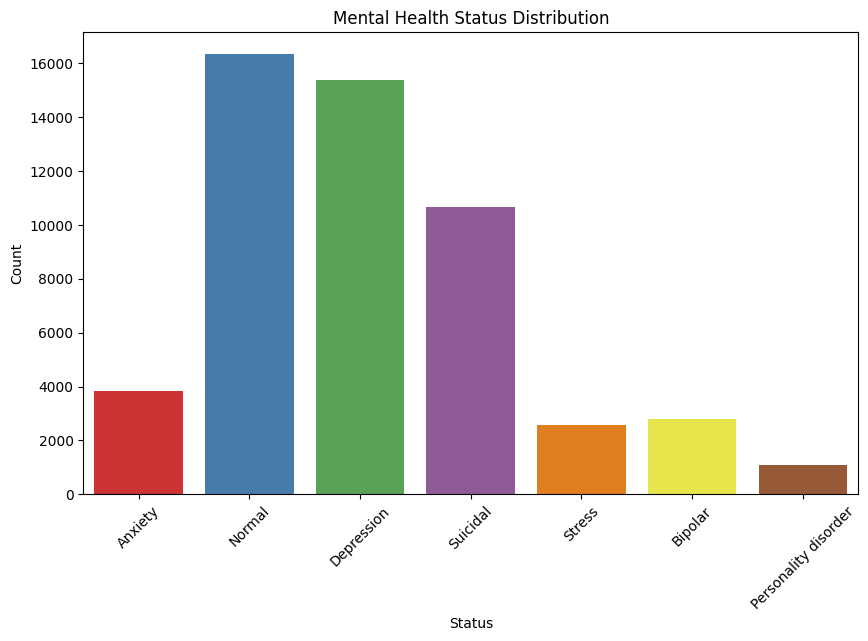

In [ ]:
# Mental health status distribution
plt.figure(figsize=(10,6))
sns.countplot(
    data=df,
    x='status',
    hue='status',
    palette="Set1"
)
plt.title("Mental Health Status Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

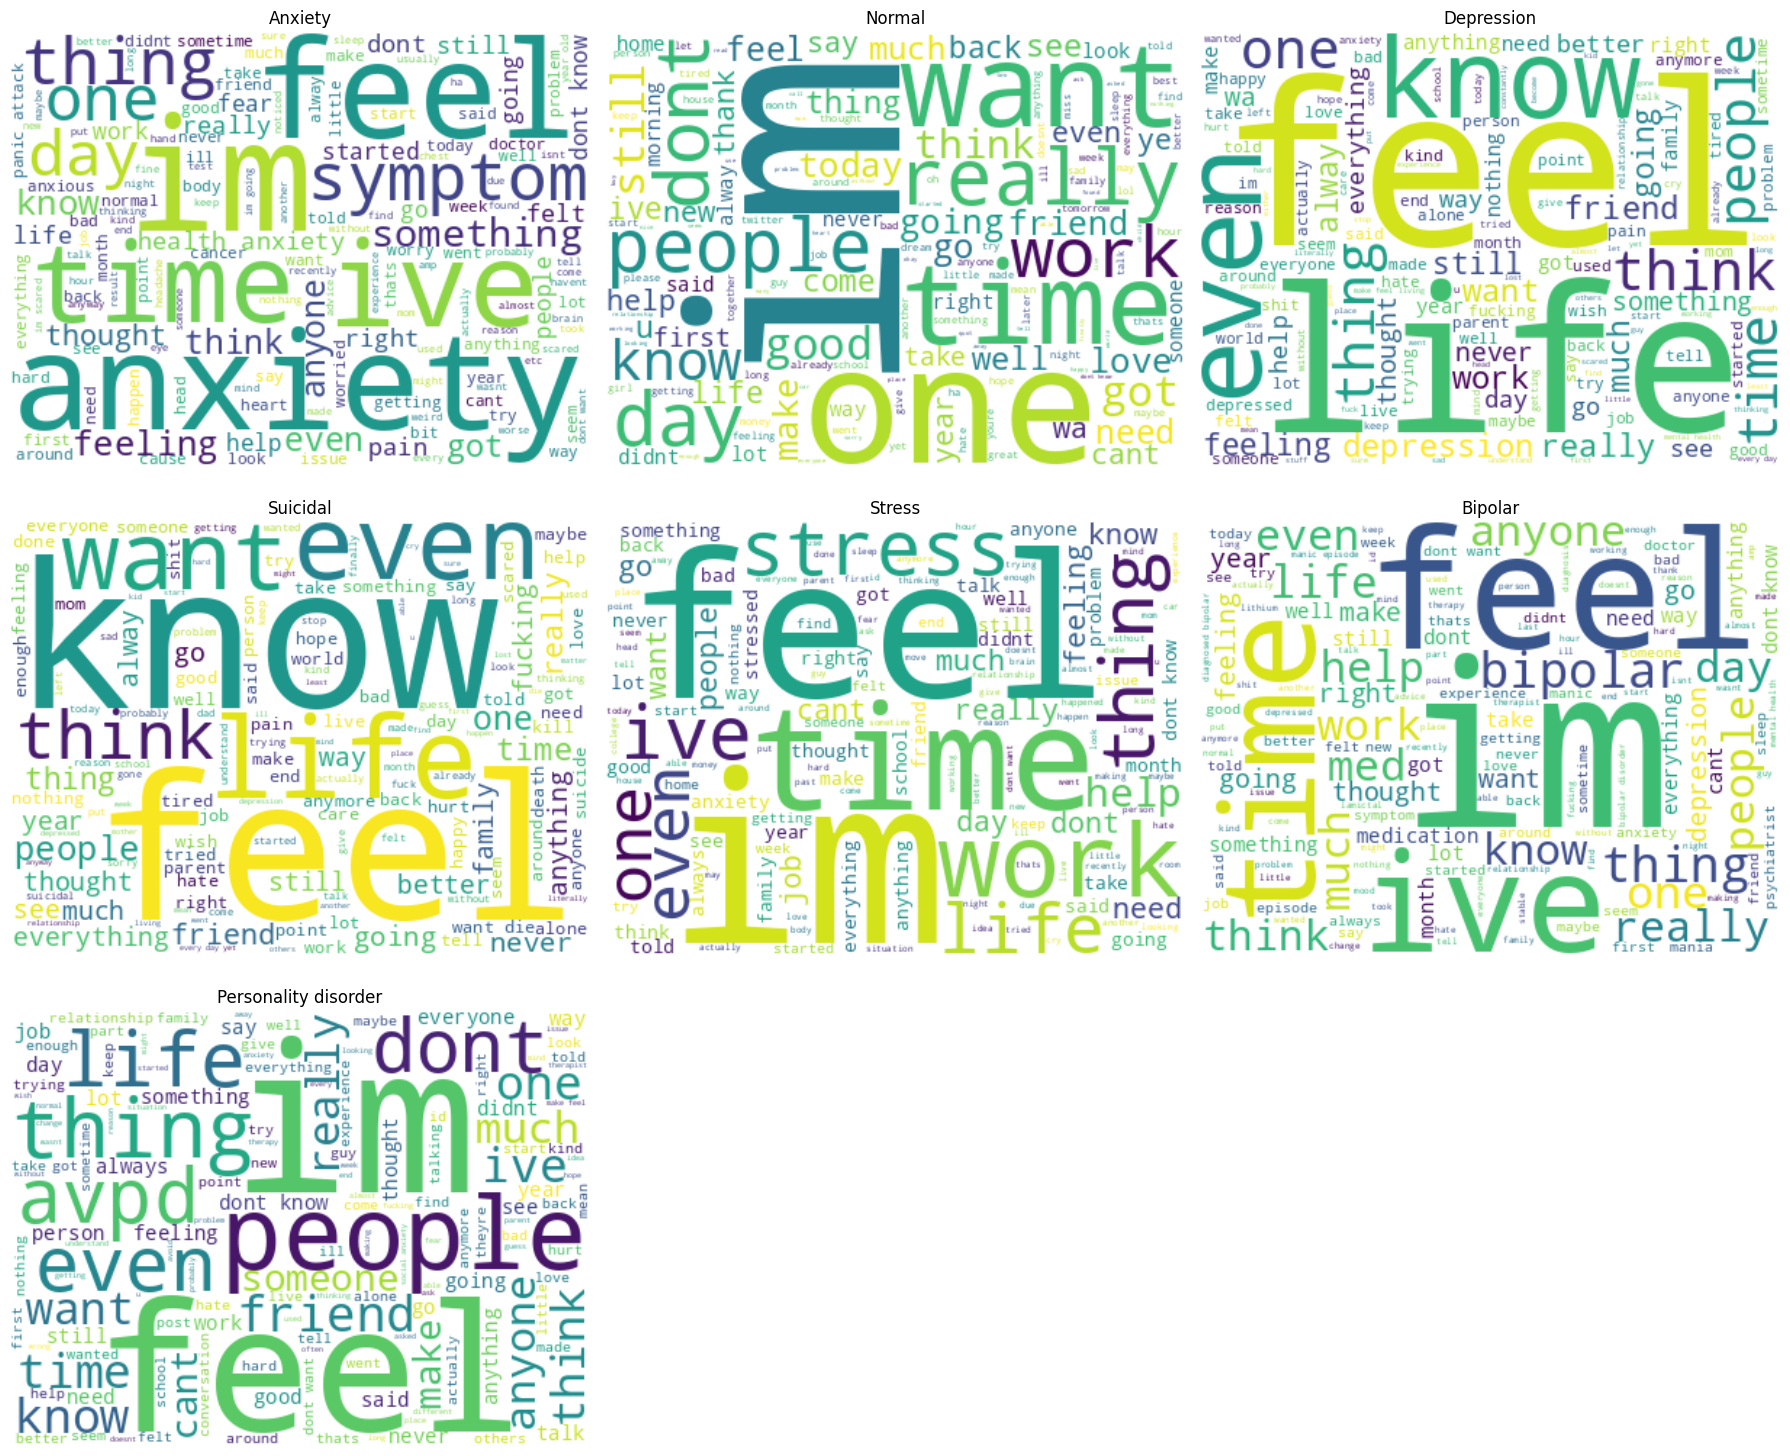

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import math

labels = df['status'].unique()
num_labels = len(labels)

cols = 3
rows = math.ceil(num_labels / cols)

plt.figure(figsize=(18, 5 * rows))

for i, label in enumerate(labels):
    text = " ".join(df[df['status'] == label]['clean_text'])

    plt.subplot(rows, cols, i + 1)

    wc = WordCloud(
        width=400,
        height=300,
        background_color="white",
        colormap="viridis",
        max_words=150
    ).generate(text)

    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"{label}")

plt.tight_layout()
plt.show()

**Feature Extraction (Vectorization)**


TF-IDF (Term Frequency–Inverse Document Frequency)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))  # unigrams + bigrams
X = tfidf.fit_transform(df['clean_text'])
y = df['statement']

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, df['status'], test_size=0.2, random_state=42, stratify=df['status'])

print('X training data size:', X_train.shape)
print('y training data size:', y_train.shape)
print('X testing data size:', X_test.shape)
print('y testing data size:', y_test.shape)
print("Data in training set:", (X_train.shape[0]/len(df.index)) * 100)
print("Data in test set:", (X_test.shape[0]/len(df.index)) * 100)

X training data size: (42144, 5000)
y training data size: (42144,)
X testing data size: (10536, 5000)
y testing data size: (10536,)
Data in training set: 80.0
Data in test set: 20.0


**Train and compare models**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_conf_matrix(y_true, y_pred, model_name, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
                xticklabels=labels,
                yticklabels=labels)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

(1) Logistic Regression

 Logistic Regression Results 
Accuracy: 0.7628132118451025

Classification Report:

                       precision    recall  f1-score   support

             Anxiety       0.82      0.75      0.78       768
             Bipolar       0.88      0.70      0.78       555
          Depression       0.71      0.74      0.72      3081
              Normal       0.84      0.95      0.89      3269
Personality disorder       0.79      0.52      0.63       215
              Stress       0.66      0.42      0.51       518
            Suicidal       0.68      0.64      0.66      2130

            accuracy                           0.76     10536
           macro avg       0.77      0.67      0.71     10536
        weighted avg       0.76      0.76      0.76     10536



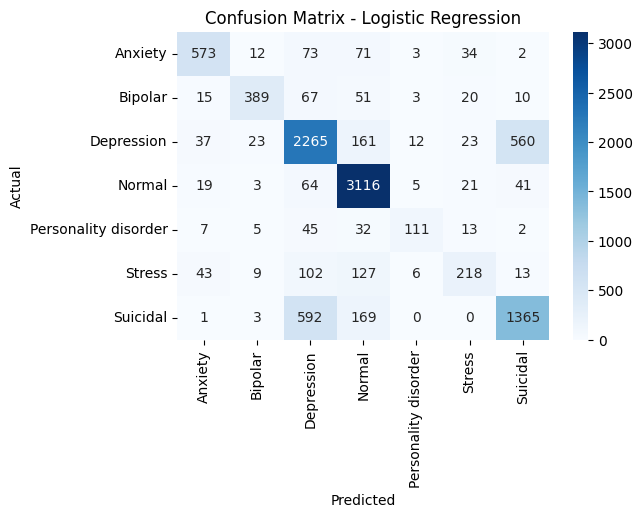

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Logistic Regression
log = LogisticRegression(max_iter=300)
log.fit(X_train, y_train)
y_pred_lr = log.predict(X_test)

print(" Logistic Regression Results ")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n\n", classification_report(y_test, y_pred_lr))

# Get the unique labels from the test set
unique_labels = sorted(y_test.unique())
plot_conf_matrix(y_test, y_pred_lr, "Logistic Regression", unique_labels)

(2) Support Vector Machine(SVM)

 SVM Results 
Accuracy: 0.7620539104024298

Classification Report:

                       precision    recall  f1-score   support

             Anxiety       0.80      0.77      0.79       768
             Bipolar       0.84      0.76      0.80       555
          Depression       0.71      0.71      0.71      3081
              Normal       0.85      0.94      0.89      3269
Personality disorder       0.79      0.63      0.70       215
              Stress       0.66      0.47      0.55       518
            Suicidal       0.66      0.64      0.65      2130

            accuracy                           0.76     10536
           macro avg       0.76      0.70      0.73     10536
        weighted avg       0.76      0.76      0.76     10536



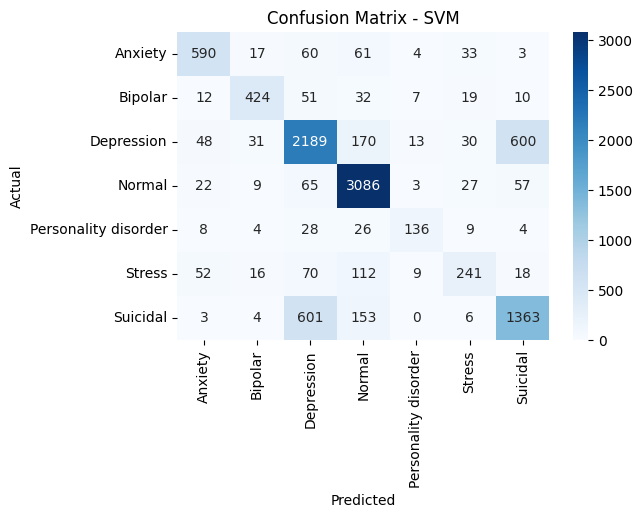

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# SVM
svm = LinearSVC()
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print(" SVM Results ")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n\n", classification_report(y_test, y_pred_svm))

# Get the unique labels from the test set
unique_labels = sorted(y_test.unique())
plot_conf_matrix(y_test,y_pred_svm,"SVM", unique_labels)

Hyperplane for Depression vs Normal

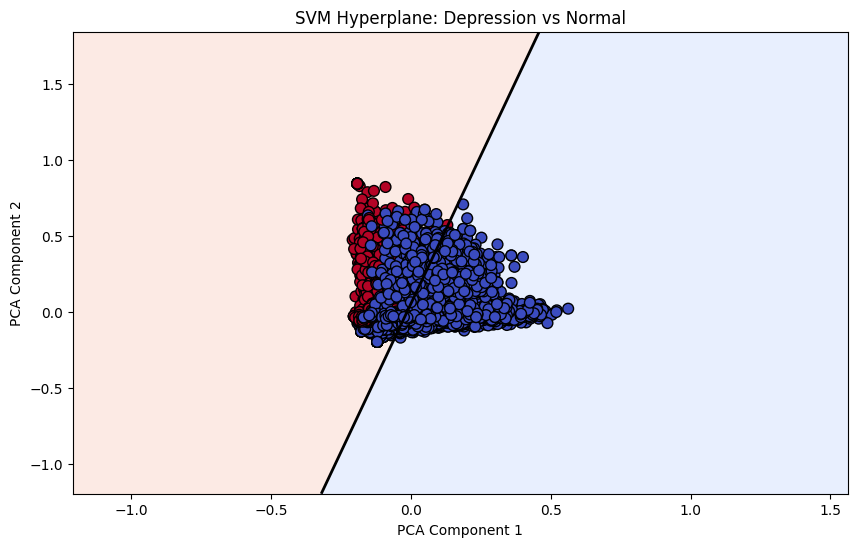

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# Select two classes
subset = df[df['status'].isin(['Depression', 'Normal'])].copy()

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=1000)
X_subset = tfidf.fit_transform(subset['clean_text'])
y_subset = subset['status']

# Encode labels
le = LabelEncoder()
y_subset_enc = le.fit_transform(y_subset)

# Reduce to 2D using PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_subset.toarray())

# Train Linear SVM
model = svm.SVC(kernel='linear')
model.fit(X_2D, y_subset_enc)

# Create meshgrid
x_min, x_max = X_2D[:, 0].min() - 1, X_2D[:, 0].max() + 1
y_min, y_max = X_2D[:, 1].min() - 1, X_2D[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict over grid
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10,6))

plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap='coolwarm')
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')

scatter = plt.scatter(
    X_2D[:, 0],
    X_2D[:, 1],
    c=y_subset_enc,
    cmap='coolwarm',
    edgecolors='k',
    s=60
)

plt.title("SVM Hyperplane: Depression vs Normal")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Hyperplane for Suicidal vs Normal

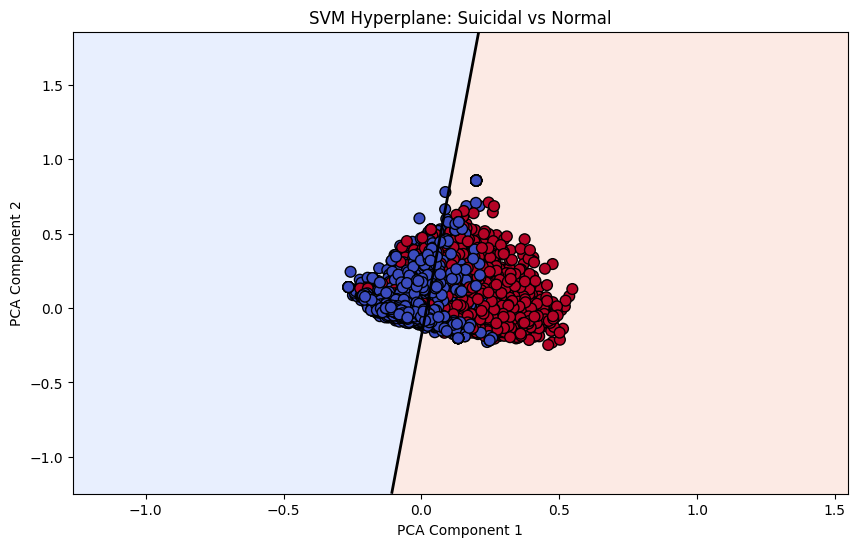

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# Select two classes
subset = df[df['status'].isin(['Suicidal', 'Normal'])].copy()

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=1000)
X_subset = tfidf.fit_transform(subset['clean_text'])
y_subset = subset['status']

# Encode labels
le = LabelEncoder()
y_subset_enc = le.fit_transform(y_subset)

# Reduce to 2D using PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_subset.toarray())

# Train Linear SVM
model = svm.SVC(kernel='linear')
model.fit(X_2D, y_subset_enc)

# Create meshgrid
x_min, x_max = X_2D[:, 0].min() - 1, X_2D[:, 0].max() + 1
y_min, y_max = X_2D[:, 1].min() - 1, X_2D[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict over grid
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10,6))

plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap='coolwarm')
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')

scatter = plt.scatter(
    X_2D[:, 0],
    X_2D[:, 1],
    c=y_subset_enc,
    cmap='coolwarm',
    edgecolors='k',
    s=60
)

plt.title("SVM Hyperplane: Suicidal vs Normal")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Hyperplane between Anxiety vs Stress

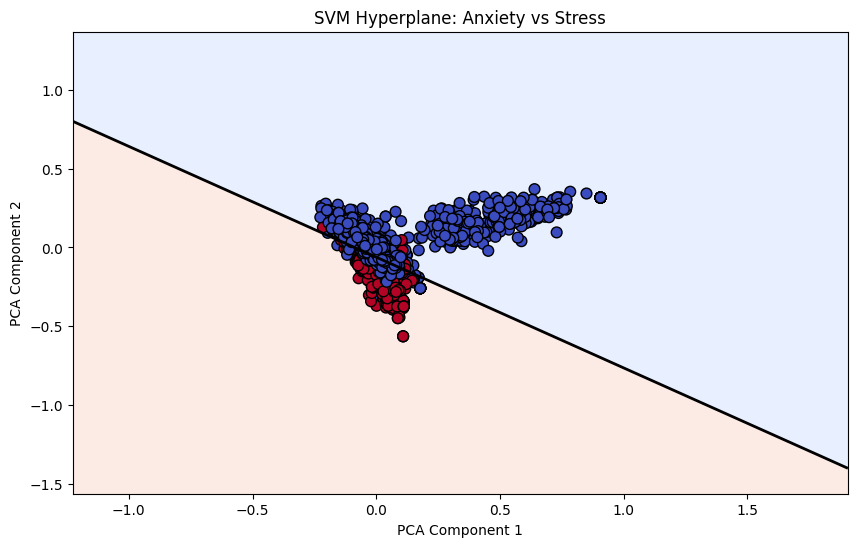

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# Select two classes
subset = df[df['status'].isin(['Anxiety', 'Stress'])].copy()

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=1000)
X_subset = tfidf.fit_transform(subset['clean_text'])
y_subset = subset['status']

# Encode labels
le = LabelEncoder()
y_subset_enc = le.fit_transform(y_subset)

# Reduce to 2D using PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_subset.toarray())

# Train Linear SVM
model = svm.SVC(kernel='linear')
model.fit(X_2D, y_subset_enc)

# Create meshgrid
x_min, x_max = X_2D[:, 0].min() - 1, X_2D[:, 0].max() + 1
y_min, y_max = X_2D[:, 1].min() - 1, X_2D[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict over grid
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10,6))

plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap='coolwarm')
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')

scatter = plt.scatter(
    X_2D[:, 0],
    X_2D[:, 1],
    c=y_subset_enc,
    cmap='coolwarm',
    edgecolors='k',
    s=60
)

plt.title("SVM Hyperplane: Anxiety vs Stress")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Hyperplane for Bipolar vs Personality disorder

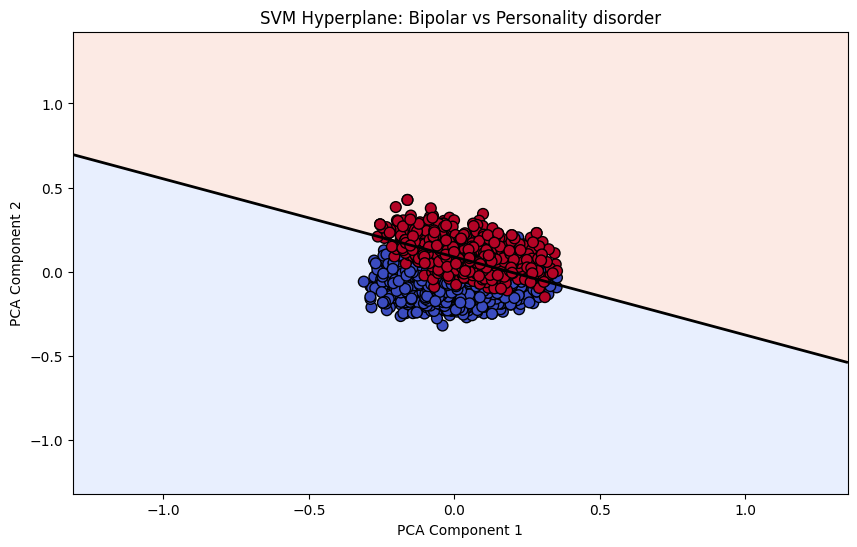

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# Select two classes
subset = df[df['status'].isin(['Bipolar', 'Personality disorder'])].copy()

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=1000)
X_subset = tfidf.fit_transform(subset['clean_text'])
y_subset = subset['status']

# Encode labels
le = LabelEncoder()
y_subset_enc = le.fit_transform(y_subset)

# Reduce to 2D using PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_subset.toarray())

# Train Linear SVM
model = svm.SVC(kernel='linear')
model.fit(X_2D, y_subset_enc)

# Create meshgrid
x_min, x_max = X_2D[:, 0].min() - 1, X_2D[:, 0].max() + 1
y_min, y_max = X_2D[:, 1].min() - 1, X_2D[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict over grid
Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(10,6))

plt.contourf(xx, yy, Z > 0, alpha=0.2, cmap='coolwarm')
plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')

scatter = plt.scatter(
    X_2D[:, 0],
    X_2D[:, 1],
    c=y_subset_enc,
    cmap='coolwarm',
    edgecolors='k',
    s=60
)

plt.title("SVM Hyperplane: Bipolar vs Personality disorder")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Comparison of Linear and RBF SVM decision boundaries

In [ ]:
# Select only two classes
binary_df = df[df['status'].isin(['Depression', 'Normal'])].copy()

# TF-IDF
tfidf = TfidfVectorizer(max_features=1000)
X_binary = tfidf.fit_transform(binary_df['clean_text'])
y_binary = binary_df['status']

# Encode labels
le = LabelEncoder()
y_binary_encoded = le.fit_transform(y_binary)

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_binary, y_binary_encoded, test_size=0.2, random_state=42
)

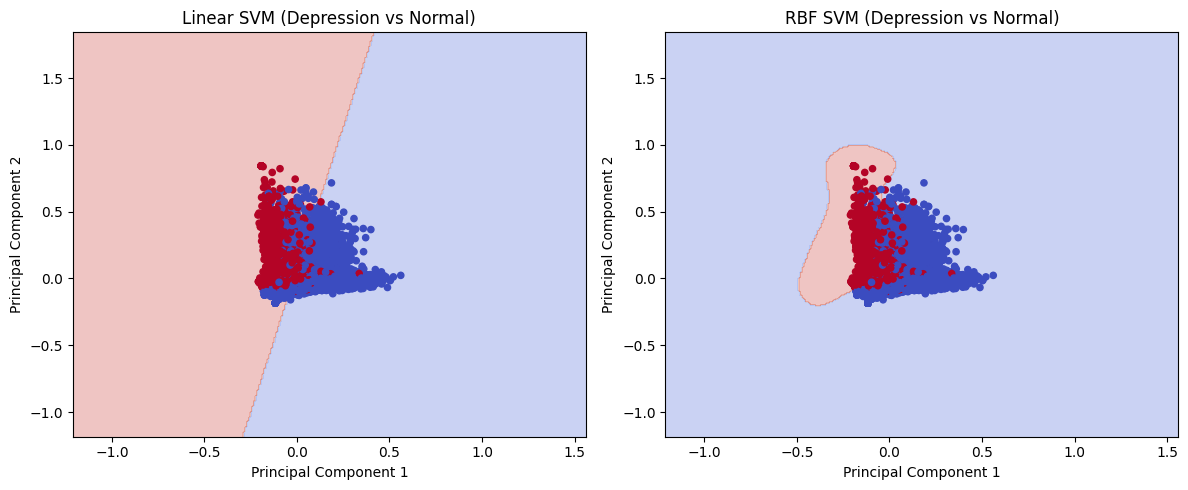

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import numpy as np

# PCA to 2D
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train.toarray())
X_test_pca = pca.transform(X_test.toarray())

# Train SVM models
svm_linear = SVC(kernel='linear', random_state=42)
svm_rbf = SVC(kernel='rbf', gamma='scale', random_state=42)

svm_linear.fit(X_train_pca, y_train)
svm_rbf.fit(X_train_pca, y_train)

# Mesh grid
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Predictions on grid
Z_linear = svm_linear.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
Z_rbf = svm_rbf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Plot
plt.figure(figsize=(12, 5))

# --- Linear ---
plt.subplot(1, 2, 1)
plt.contourf(xx, yy, Z_linear, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
            c=y_train, cmap='coolwarm', s=20)
plt.title("Linear SVM (Depression vs Normal)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# --- RBF ---
plt.subplot(1, 2, 2)
plt.contourf(xx, yy, Z_rbf, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
            c=y_train, cmap='coolwarm', s=20)
plt.title("RBF SVM (Depression vs Normal)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

Due to the high dimensional sparse nature of TF-IDF features, linear SVM performs competitively with RBF kernel.

(3) Random Forest Classifier

Random Forest Results
Accuracy: 0.9384251968503937

Classification Report:

              precision    recall  f1-score   support

  Depression       0.94      0.94      0.94      3095
      Normal       0.94      0.94      0.94      3255

    accuracy                           0.94      6350
   macro avg       0.94      0.94      0.94      6350
weighted avg       0.94      0.94      0.94      6350



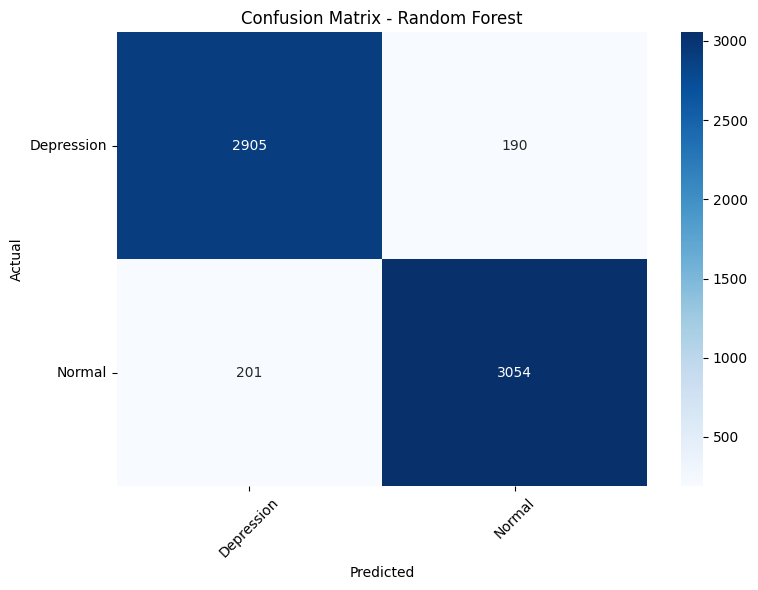

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

# Accuracy
print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

# Classification Report
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=le.classes_
))

# Confusion Matrix (Seaborn Style)
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

We have compared all the 3 models and we can say that accuracy is high in the **Logistic Regression**

**Train XGBoost**

Redefine train_test_split

In [ ]:
import pandas as pd
import re
import nltk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download NLTK resources (only first run)
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    return " ".join(tokens)

df = pd.read_csv("Combined Data.csv")   # change if filename different

# Remove missing values
df = df.dropna(subset=['statement', 'status'])

# Clean text
df['clean_text'] = df['statement'].apply(clean_text)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)
)

X = tfidf.fit_transform(df['clean_text'])
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('X training data size:', X_train.shape)
print('y training data size:', y_train.shape)
print('X testing data size:', X_test.shape)
print('y testing data size:', y_test.shape)

print("Training %:", (X_train.shape[0]/len(df)) * 100)
print("Testing %:", (X_test.shape[0]/len(df)) * 100)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


X training data size: (42144, 5000)
y training data size: (42144,)
X testing data size: (10536, 5000)
y testing data size: (10536,)
Training %: 80.0
Testing %: 20.0


Encode & Train XGBoost

XGBoost Results
Accuracy: 0.7757213363705391

Classification Report:

                      precision    recall  f1-score   support

             Anxiety       0.82      0.78      0.80       768
             Bipolar       0.88      0.78      0.83       555
          Depression       0.73      0.74      0.74      3081
              Normal       0.83      0.94      0.88      3269
Personality disorder       0.87      0.63      0.73       215
              Stress       0.64      0.55      0.59       518
            Suicidal       0.71      0.64      0.67      2130

            accuracy                           0.78     10536
           macro avg       0.78      0.72      0.75     10536
        weighted avg       0.77      0.78      0.77     10536



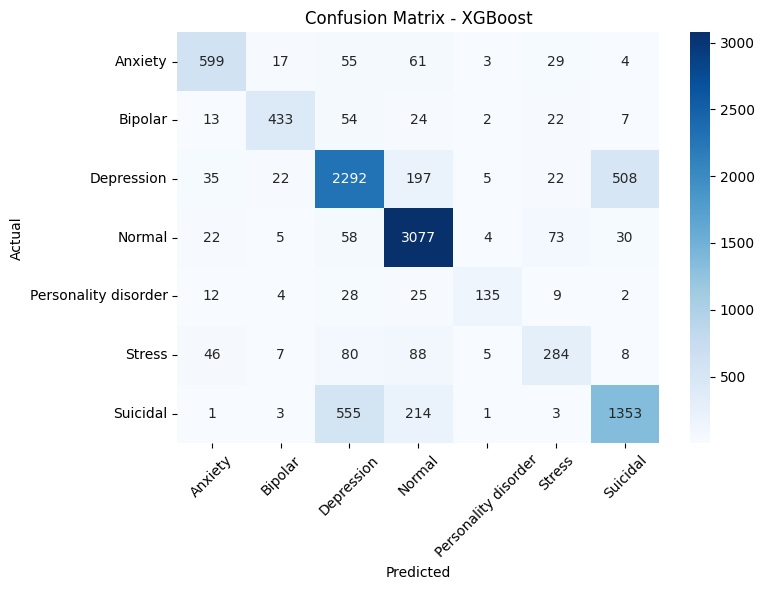

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(X_train, y_train_encoded)

y_pred_encoded = xgb.predict(X_test)

print("XGBoost Results")
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_encoded))

print("\nClassification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred_encoded,
    target_names=le.classes_
))

cm_xgb = confusion_matrix(y_test_encoded, y_pred_encoded)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Compare Model Performances in a Bar Chart**

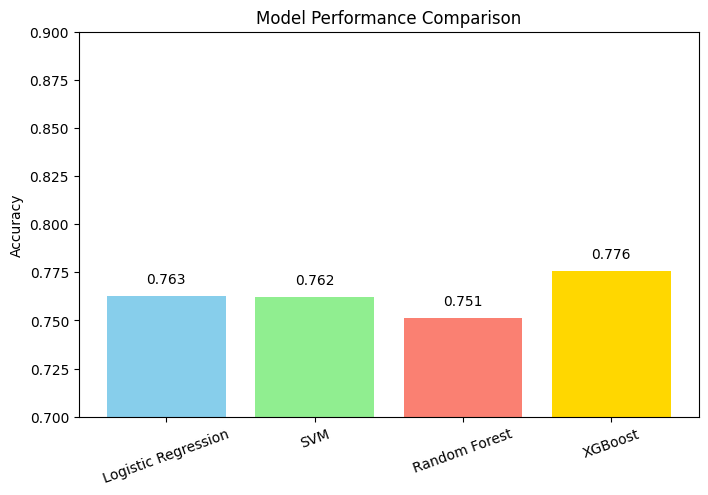

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# Logistic Regression
log = LogisticRegression(max_iter=300)
log.fit(X_train, y_train_enc)
y_pred_lr = log.predict(X_test)

# SVM
svm = LinearSVC()
svm.fit(X_train, y_train_enc)
y_pred_svm = svm.predict(X_test)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)
rf.fit(X_train, y_train_enc)
y_pred_rf = rf.predict(X_test)

# XGBoost
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(X_train, y_train_enc)
y_pred_xgb = xgb.predict(X_test)

results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM", "Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test_enc, y_pred_lr),
        accuracy_score(y_test_enc, y_pred_svm),
        accuracy_score(y_test_enc, y_pred_rf),
        accuracy_score(y_test_enc, y_pred_xgb)
    ]
})

# Plot comparison
plt.figure(figsize=(8,5))
bars = plt.bar(results_df["Model"],
               results_df["Accuracy"],
               color=["skyblue","lightgreen","salmon","gold"])

plt.title("Model Performance Comparison")
plt.ylabel("Accuracy")
plt.ylim(0.7, 0.90)

# Add values above bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.005,
             f"{bar.get_height():.3f}",
             ha="center",
             va="bottom",
             fontsize=10)

plt.xticks(rotation=20)
plt.show()

Although the other models performed well and produced reliable results, **XGBoost** outperformed them in terms of overall accuracy. This suggests that the gradient boosting approach was better able to model the underlying patterns and non-linear relationships present in the text data.

**Explainable AI (XAI)** : So far, we only know what prediction the models gave (positive/negative/neutral), but we don’t know why they gave that prediction.

This is where Explainable AI (XAI) comes in. It allows us to “peek inside the black box” of ML models.

**LIME (Local Interpretable Model-Agnostic Explanations)** to explain why a specific tweet is classified as positive, negative, or neutral

In [ ]:
!pip install lime --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 16.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import random
import numpy as np
from lime.lime_text import LimeTextExplainer
from sklearn.pipeline import make_pipeline

In [ ]:
# Class names
class_names = sorted(df['status'].unique().tolist())

# Pipeline (TF-IDF + Logistic Regression)
pipeline = make_pipeline(tfidf, log)

# Initialize LIME
explainer = LimeTextExplainer(class_names=class_names)

# Pick random test instance
idx = np.random.randint(0, len(y_test))
text_instance = df.loc[y_test.index[idx], "statement"]

print(f"Random Sentence Index: {idx}")
print("Sentence:", text_instance)
print("True Label:", y_test.iloc[idx])

#  Get predicted probabilities
probs = pipeline.predict_proba([text_instance])[0]
predicted_class_index = np.argmax(probs)
predicted_class_name = class_names[predicted_class_index]

print("Predicted Label:", predicted_class_name)
print("Prediction Probabilities:", probs)

# Explain predicted class ONLY
exp = explainer.explain_instance(
    text_instance,
    pipeline.predict_proba,
    labels=[predicted_class_index],
    num_features=10
)

exp.show_in_notebook(text=True)

Random Sentence Index: 1614
Sentence: I am 24. But I cannot take care of myself. I cannot live on my own. I have no one to help me. I think I should just kill myself. I do not know what else to do. I am in a helpless situation. I am thinking about killing myself
True Label: Suicidal
Predicted Label: Suicidal
Prediction Probabilities: [2.59654720e-04 2.24272751e-04 8.13789072e-02 7.57085342e-04
 2.73417824e-04 1.29647710e-03 9.15810185e-01]


**SHAP (SHapley Additive exPlanations)**

While LIME explains one prediction at a time, SHAP explains the entire model’s behavior — i.e. which words overall most influence sentiment predictions across the dataset.

In [ ]:
!pip install shap --quiet

Number of TF-IDF features: 5000


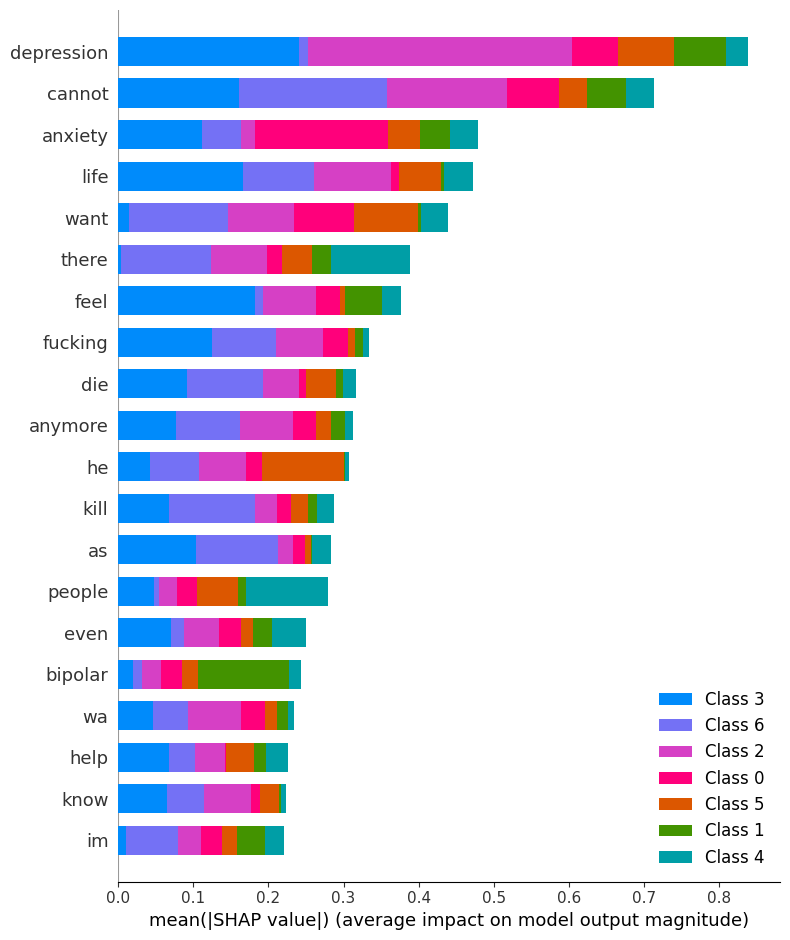

In [ ]:
import shap
import numpy as np
from sklearn.model_selection import train_test_split

# Prepare data (raw text)
X_text = df['statement']
y = df['status']

# Train-test split (same structure as before)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Extract model & vectorizer from pipeline
model = pipeline.named_steps['logisticregression']
vectorizer = pipeline.named_steps['tfidfvectorizer']

# Transform again properly
X_train_tfidf = vectorizer.transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# Now slice
X_train_sample = X_train_tfidf[:1000].toarray()
X_test_sample = X_test_tfidf[:200].toarray()

# Feature names (words + bigrams)
feature_names = vectorizer.get_feature_names_out()
print("Number of TF-IDF features:", len(feature_names))

# Create SHAP explainer (Linear model)
explainer = shap.Explainer(
    model,
    X_train_sample,
    feature_names=feature_names
)

# Compute SHAP values
shap_values = explainer(X_test_sample)
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=feature_names
)

The multi-class mental health classification model effectively categorized text into seven psychological states using TF-IDF features and multiple machine learning algorithms. Among the models evaluated, **XGBoost achieved the highest overall accuracy**, outperforming Logistic Regression, SVM, and Random Forest.

While the other models performed well, XGBoost demonstrated stronger predictive capability in distinguishing between closely related mental health categories.

The integration of LIME and SHAP further enhanced interpretability by highlighting the key words influencing each prediction.

Overall, the project demonstrates that advanced ensemble methods combined with interpretable NLP techniques can effectively classify mental health-related text while maintaining transparency in decision-making.

Future work could explore transformer-based architectures such as BERT or RoBERTa for deeper contextual understanding and investigate temporal modeling approaches to detect early warning signals of mental health deterioration over time.